# PathSnap — 02 · Labelling, Candidate Generation & Feature Engineering

**Partitions used:** `train` for every design decision (radius, K, thresholds); `student_test` only for reporting.
The evaluator partition is never touched.

The task is framed as **binary classification over (GPS point, candidate road arc) pairs**:
for each GPS point we list nearby arcs and the model scores how likely each one is the arc the vehicle was on.
The HMM in stage 7 then uses these scores as emission probabilities.

Pipeline (code in `src/`, built by `scripts/build_features.py`):
1. `labels.py` — assign every GPS point a ground-truth arc from the `.route` file (order-preserving alignment)
2. `candidates.py` — candidate arcs within radius **R** of each point, nearest **K** kept
3. `features.py` — 26 features per pair, from GPS and road network only (no route information)

In [1]:
import os, sys, json, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, folium
from src.data_io import Trip
from src.labels import align_points_to_route
from src.candidates import TripGraph
from src.features import FEATURES
from src.viz import base_map, arcs_to_lines, COLORS, _legend
FIG = '../outputs/features/figures'; MAPS = '../outputs/features/maps'; FEAT = '../outputs/features'
os.makedirs(FIG, exist_ok=True); os.makedirs(MAPS, exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 200)
PAL = {'train': '#1f5fd6', 'student_test': '#e8590c'}
def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG}/{name}.png', dpi=150, bbox_inches='tight'); plt.show()
cfg = json.load(open(f'{FEAT}/config.json')); cfg

{'radius_m': 50.0,
 'k': 12,
 'k_fallback': 3,
 'sigma_m': 5.0,
 'min_move_m': 2.0,
 'unreliable_trip_median_m': 30.0,
 'features': ['dist',
  'dist_rank',
  'dist_minus_min',
  'dist_ratio_min',
  'gauss_share',
  'n_cands',
  'proj_frac',
  'dist_to_end_min',
  'arc_len',
  'heading_diff',
  'heading_diff_undirected',
  'heading_reliable',
  'speed',
  'accel',
  'dt_prev',
  'dt_next',
  'turn_rate',
  'dist_prev1',
  'dist_prev2',
  'dist_next1',
  'dist_next2',
  'ctx_mean_dist',
  'from_out_deg',
  'to_in_deg',
  'to_out_deg',
  'has_reverse']}

## 1. Point-level labels from the reference route

`.route` lists ~5× fewer arcs than there are GPS points, and some routes drive the same arc twice, so "nearest route arc"
is not a safe label. Instead each trip is aligned with a **monotonic dynamic programme**:

$$D[i,j] = d(i,j) + \min_{k \le j} D[i-1,k]$$

where $d(i,j)$ is the distance (m) from point $i$ to the $j$-th arc of the route. Backtracking gives the order-preserving
assignment with the smallest total distance. Labels are therefore *derived*, and inherit the reference route's limitations.

In [2]:
summ = pd.read_csv(f'{FEAT}/trip_summary.csv', dtype={'trip': str})
cov = []
for r in summ.itertuples():
    t = Trip(r.trip, r.partition); lab = align_points_to_route(t)
    cov.append(dict(trip=r.trip, monotone=bool(np.all(np.diff(lab['route_pos']) >= 0)),
                    route_arcs_with_points=len(np.unique(lab['route_pos'])) / len(t.route)))
summ = summ.merge(pd.DataFrame(cov), on='trip')
print('All alignments order-preserving:', summ.monotone.all())
print(f"Share of route arcs that receive >=1 GPS point: median {summ.route_arcs_with_points.median():.1%} "
      "(short arcs crossed in under 1 s get no point, which is expected)")
summ[['partition', 'median_label_dist', 'pct_points_label_far', 'route_arcs_with_points']].groupby('partition').describe().T.round(2)

All alignments order-preserving: True
Share of route arcs that receive >=1 GPS point: median 92.4% (short arcs crossed in under 1 s get no point, which is expected)


partition                     student_test   train
median_label_dist      count         10.00   80.00
                       mean           5.09    8.16
                       std            0.91   19.92
                       min            4.18    3.45
                       25%            4.43    4.29
                       50%            4.75    4.64
                       75%            5.77    5.55
                       max            6.85  140.09
pct_points_label_far   count         10.00   80.00
                       mean           0.07    2.49
                       std            0.22   11.97
                       min            0.00    0.00
                       25%            0.00    0.00
                       50%            0.00    0.00
                       75%            0.00    0.06
                       max            0.68   89.44
route_arcs_with_points count         10.00   80.00
                       mean           0.90    0.90
                       std            0.06    0.07
                       min            0.79    0.67
                       25%            0.87    0.87
                       50%            0.89    0.92
                       75%            0.96    0.96
                       max            0.98    1.00

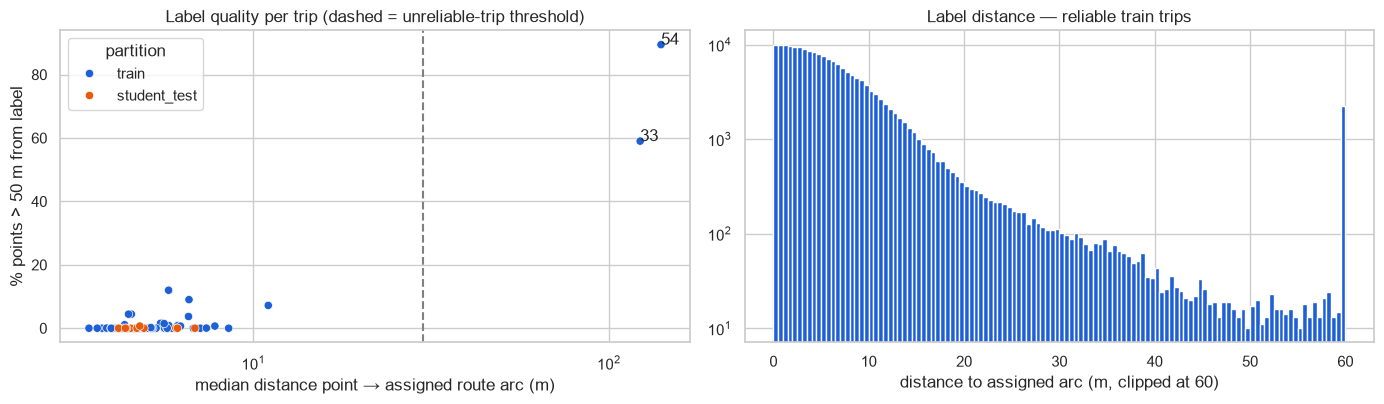

Reliable train points: 183260;  median 4.96 m;  > 50 m: 1.39%
Unreliable trips (excluded from training): ['00000033', '00000054']


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sns.scatterplot(data=summ, x='median_label_dist', y='pct_points_label_far', hue='partition', palette=PAL, ax=ax[0])
ax[0].set_xscale('log'); ax[0].axvline(cfg['unreliable_trip_median_m'], ls='--', c='grey')
ax[0].set_xlabel('median distance point → assigned route arc (m)'); ax[0].set_ylabel(f"% points > {cfg['radius_m']:.0f} m from label")
ax[0].set_title('Label quality per trip (dashed = unreliable-trip threshold)')
for r in summ[~summ.trip_reliable].itertuples(): ax[0].annotate(r.trip[-2:], (r.median_label_dist, r.pct_points_label_far))
tr = pd.read_parquet(f'{FEAT}/train.parquet', columns=['trip', 'point_idx', 'label_dist', 'trip_reliable'])
ld = tr[tr.trip_reliable == 1].drop_duplicates(['trip', 'point_idx']).label_dist
ax[1].hist(np.clip(ld, 0, 60), bins=120, color=PAL['train']); ax[1].set_yscale('log')
ax[1].set_xlabel('distance to assigned arc (m, clipped at 60)'); ax[1].set_title('Label distance — reliable train trips')
savefig('01_label_quality')
print(f"Reliable train points: {len(ld)};  median {ld.median():.2f} m;  > {cfg['radius_m']:.0f} m: {(ld > cfg['radius_m']).mean():.2%}")
print('Unreliable trips (excluded from training):', summ.loc[~summ.trip_reliable, 'trip'].tolist())

**Decisions**
- Trips whose median point-to-label distance is above 30 m (**33, 54**) are flagged `trip_reliable = 0` and excluded from
  training. In EDA, trip 54 showed a ~130 m systematic GPS offset and trip 33 showed GPS following roads that are not on the reference route.
- Individual points more than R m from their label get `label_ok = 0`. Their true arc cannot be in the candidate set, so
  they carry no positive example.

## 2. Candidate generation — choosing radius R and cap K (train only)

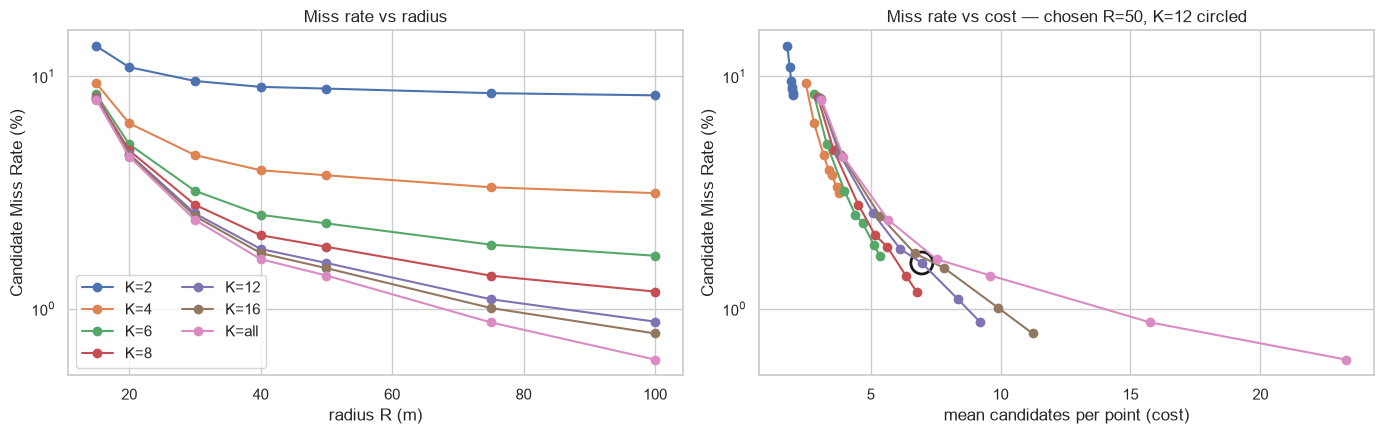

K_label,12,16,2,4,6,8,all
R,,,,,,,
15,8.02,7.98,13.45,9.30,8.35,8.13,7.93
20,4.62,4.58,10.92,6.27,5.09,4.79,4.51
30,2.57,2.50,9.53,4.57,3.21,2.80,2.41
40,1.81,1.73,8.99,3.94,2.53,2.07,1.63
50,1.57,1.49,8.84,3.75,2.33,1.85,1.39
75,1.10,1.01,8.45,3.33,1.88,1.39,0.87
100,0.88,0.78,8.27,3.14,1.69,1.18,0.60


In [4]:
sw = pd.read_csv(f'{FEAT}/candidate_sweep_train.csv', dtype={'trip': str})
sw = sw[sw.reliable_trip].groupby(['R', 'K'])[['hits', 'n_points', 'n_cands']].sum()
sw['miss_rate_%'] = (1 - sw.hits / sw.n_points) * 100; sw['cands_per_point'] = sw.n_cands / sw.n_points
sw = sw.reset_index(); sw['K_label'] = sw.K.replace({1000: 'all'}).astype(str)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k, g in sw.groupby('K_label', sort=False):
    ax[0].plot(g.R, g['miss_rate_%'], marker='o', label=f'K={k}')
    ax[1].plot(g.cands_per_point, g['miss_rate_%'], marker='o', label=f'K={k}')
for a in ax: a.set_ylabel('Candidate Miss Rate (%)'); a.set_yscale('log')
ax[0].set_xlabel('radius R (m)'); ax[0].legend(ncol=2); ax[0].set_title('Miss rate vs radius')
ax[1].set_xlabel('mean candidates per point (cost)'); ax[1].set_title('Miss rate vs cost — chosen R=50, K=12 circled')
c = sw[(sw.R == cfg['radius_m']) & (sw.K == cfg['k'])].iloc[0]
ax[1].scatter(c.cands_per_point, c['miss_rate_%'], s=250, facecolors='none', edgecolors='k', lw=2)
savefig('02_candidate_sweep')
sw.pivot(index='R', columns='K_label', values='miss_rate_%').round(2)

R = 50 m with K = 12 misses ~1.6% of points at ~7 candidates per point. Going to 75 m only gains ~0.5 pp at +20% rows,
and the EDA showed 98% of reliable points lie within 30 m of the route. K=2 still misses ~9%: the true road is frequently
*not* the nearest one, which is exactly what the classifier must learn. In the final tables, points with nothing inside
50 m fall back to their 3 nearest arcs (`fallback = True`), so every point has at least one HMM state.

In [5]:
s = summ.copy()
print('Candidate Miss Rate (point-weighted) with the chosen configuration:')
for (p, rel), g in s.groupby(['partition', 'trip_reliable']):
    print(f'  {p:13s} reliable={rel!s:5s}  trips={len(g):2d}  miss={np.average(g.candidate_miss_rate, weights=g.n_points):.2%}'
          f'  cands/point={np.average(g.cands_per_point, weights=g.n_points):.2f}')

Candidate Miss Rate (point-weighted) with the chosen configuration:
  student_test  reliable=True   trips=10  miss=0.21%  cands/point=7.67
  train         reliable=False  trips= 2  miss=85.17%  cands/point=4.60
  train         reliable=True   trips=78  miss=0.90%  cands/point=6.99


## 3. Feature table

In [6]:
train = pd.read_parquet(f'{FEAT}/train.parquet'); test = pd.read_parquet(f'{FEAT}/student_test.parquet')
trn = train[(train.trip_reliable == 1)]
print(f'train rows {len(train):,} (reliable trips {len(trn):,});  student_test rows {len(test):,}')
print(f'positive rate: train {trn.y.mean():.3f}   student_test {test.y.mean():.3f}   (imbalanced, about 1 : 6.5)')
print('NaN values in features:', int(train[FEATURES].isna().sum().sum() + test[FEATURES].isna().sum().sum()))
desc = pd.DataFrame({'group': ['geometry'] * 9 + ['direction'] * 3 + ['motion'] * 5 + ['context'] * 5 + ['topology'] * 4}, index=FEATURES)
desc['median | y=1'] = trn[trn.y == 1][FEATURES].median(); desc['median | y=0'] = trn[trn.y == 0][FEATURES].median()
desc.round(3)

train rows 1,397,323 (reliable trips 1,281,584);  student_test rows 146,925
positive rate: train 0.142   student_test 0.130   (imbalanced, about 1 : 6.5)
NaN values in features: 0


,group,median | y=1,median | y=0
dist,geometry,4.909,21.168
dist_rank,geometry,0.000,4.000
dist_minus_min,geometry,0.000,15.237
dist_ratio_min,geometry,1.000,3.654
gauss_share,geometry,0.500,0.000
n_cands,geometry,6.000,12.000
proj_frac,geometry,0.500,0.491
dist_to_end_min,geometry,20.590,0.000
arc_len,geometry,100.187,38.242
heading_diff,direction,13.413,99.830


| Group | Features | Why |
|---|---|---|
| Geometry | `dist`, `dist_rank`, `dist_minus_min`, `dist_ratio_min`, `gauss_share`, `n_cands`, `proj_frac`, `dist_to_end_min`, `arc_len` | GPS noise is roughly Gaussian (median ≈ 5 m), so closeness matters, but *relative* to the other candidates. `gauss_share` is a Gaussian-likelihood share among a point's candidates (σ = 5 m) |
| Direction | `heading_diff` (0–180°, uses arc direction), `heading_diff_undirected`, `heading_reliable` | Separates parallel and crossing roads, and opposite carriageways. The heading is unreliable when the vehicle barely moves |
| Motion | `speed`, `accel`, `dt_prev`, `dt_next`, `turn_rate` | Gaps (EDA: 3% of steps > 1 s) and turns make geometry less trustworthy |
| Context | `dist_prev1/2`, `dist_next1/2`, `ctx_mean_dist` | A true arc also stays near neighbouring GPS points. This suppresses side streets the vehicle only passes |
| Topology | `from_out_deg`, `to_in_deg`, `to_out_deg`, `has_reverse` | Intersections and two-way roads are where errors concentrate |

No feature uses the reference route, so the same code runs in the API at inference time.

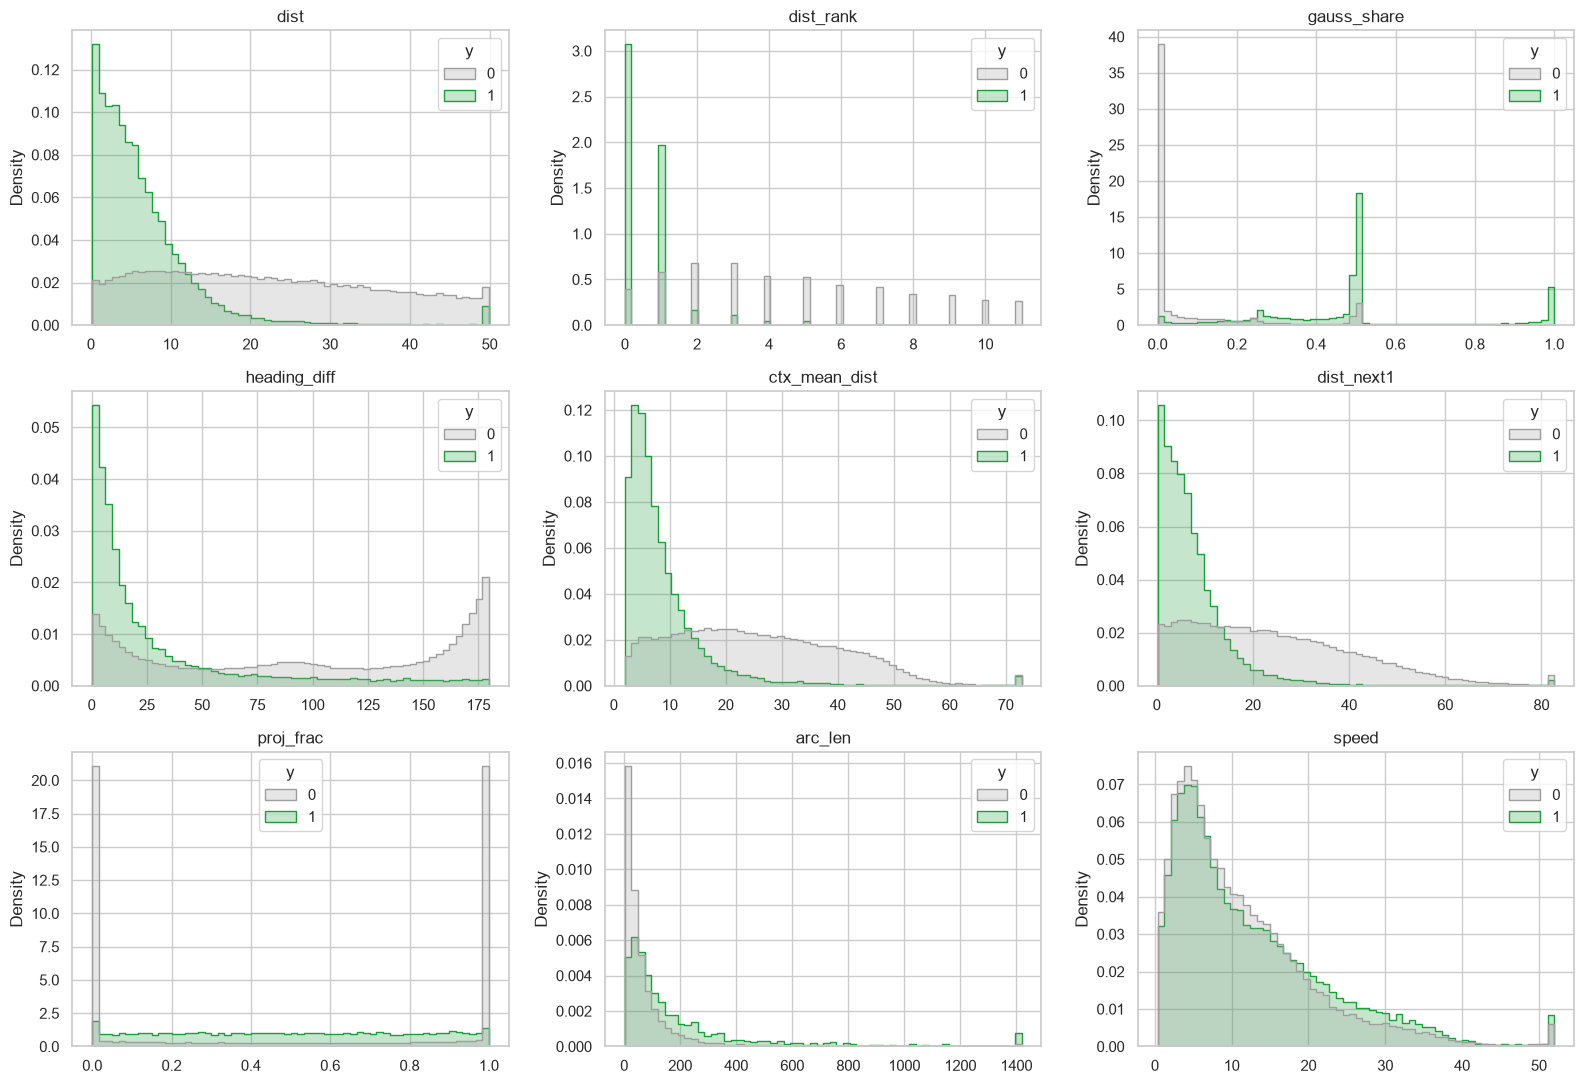

In [7]:
show = ['dist', 'dist_rank', 'gauss_share', 'heading_diff', 'ctx_mean_dist', 'dist_next1', 'proj_frac', 'arc_len', 'speed']
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
smp = trn.sample(200_000, random_state=0)
for ax, f in zip(axes.ravel(), show):
    lo, hi = np.nanpercentile(smp[f], [0.5, 99.5])
    sns.histplot(data=smp, x=np.clip(smp[f], lo, hi), hue='y', stat='density', common_norm=False, bins=60,
                 element='step', palette={0: '#9e9e9e', 1: COLORS['reference']}, ax=ax)
    ax.set_title(f); ax.set_xlabel('')
savefig('03_feature_distributions_by_class')

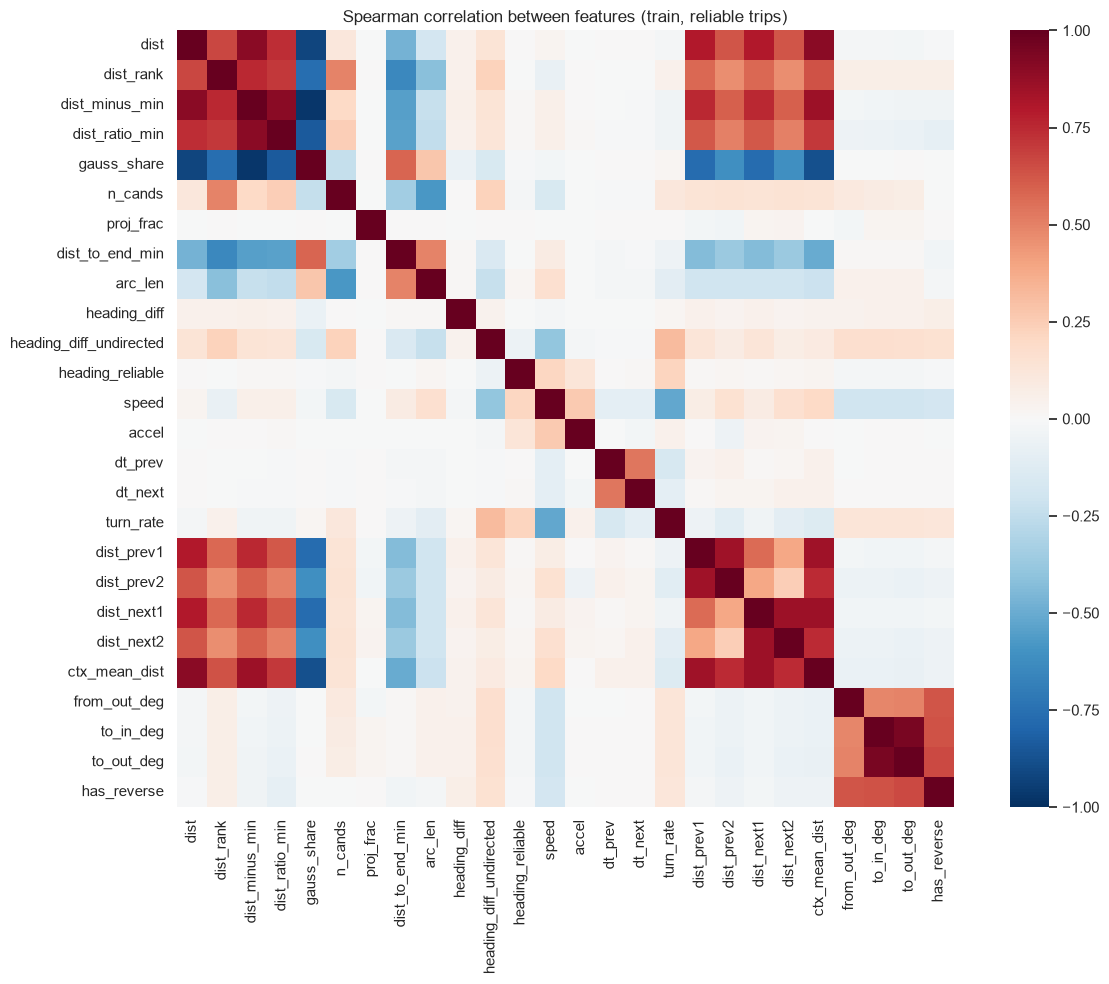

In [8]:
plt.figure(figsize=(13, 10))
sns.heatmap(trn[FEATURES].sample(200_000, random_state=0).corr(method='spearman'), cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True)
plt.title('Spearman correlation between features (train, reliable trips)')
savefig('04_feature_correlation')

## 4. Rule-based baselines (no learning)

A floor that every ML model in stage 4 must beat. **Top-1 accuracy** = share of GPS points whose highest-scoring candidate is
the true arc (points whose true arc is missing from the candidate set count as errors).

In [9]:
def top1(df, score):
    best = df.loc[df.assign(s=score).groupby(['trip', 'point_idx']).s.idxmax()]
    return best.y.mean()
rules = {
    'nearest arc': lambda d: -d.dist,
    'nearest + heading': lambda d: -(d.dist / 5.0) ** 2 / 2 - (d.heading_diff / 30.0) ** 2 / 2,
    'nearest + heading + context': lambda d: -(d.ctx_mean_dist / 5.0) ** 2 / 2 - (d.heading_diff / 30.0) ** 2 / 2,
}
res = pd.DataFrame({name: {'train (reliable)': top1(trn, f(trn)), 'student_test': top1(test, f(test))} for name, f in rules.items()}).T
(res * 100).round(2).rename(columns=lambda c: c + ' Top-1 %')

,train (reliable) Top-1 %,student_test Top-1 %
nearest arc,55.73,53.83
nearest + heading,81.61,83.26
nearest + heading + context,80.23,81.92


**Why is "nearest arc" only about 55%?** Two-way streets are stored as **two directed arcs with identical geometry**, (u→v) and (v→u).
Both are exactly the same distance from the GPS point, so distance alone cannot separate them and the tie is broken arbitrarily.
Adding heading (`heading_diff` uses the arc's direction) resolves this and lifts Top-1 to about 82%. The remaining errors are at
intersections and on parallel roads. This motivates a learned combination of all features (stage 4) and sequence decoding with
road connectivity (stage 7). The hand-weighted context rule is slightly *worse* than heading alone, which shows that the weights
need to be learned rather than guessed.

## 5. Map — where nearest-arc snapping fails

In [10]:
tid, part = '00000075', 'train'
t = Trip(tid, part); d = train[train.trip == tid]
near = d.loc[d.groupby('point_idx').dist.idxmin()].set_index('point_idx')
m = base_map(); tr = t.track
m.fit_bounds([[tr.lat.min(), tr.lon.min()], [tr.lat.max(), tr.lon.max()]])
fg = folium.FeatureGroup('Reference route'); folium.PolyLine(arcs_to_lines(t, t.route), color=COLORS['reference'], weight=6, opacity=0.6).add_to(fg); fg.add_to(m)
wrong = near[near.y == 0]
fg = folium.FeatureGroup('Nearest arc chosen (wrong)'); folium.PolyLine(arcs_to_lines(t, wrong.arc_id.unique()), color='#c2255c', weight=3).add_to(fg); fg.add_to(m)
for ok, name, col in [(1, 'GPS — nearest arc correct', '#1f5fd6'), (0, 'GPS — nearest arc wrong', '#c2255c')]:
    fg = folium.FeatureGroup(name)
    for i in near.index[near.y == ok]:
        folium.CircleMarker([tr.lat[i], tr.lon[i]], radius=3, color=col, fill=True, fill_opacity=0.9, weight=0,
                            tooltip=f'pt {i}, dist {near.dist[i]:.1f} m').add_to(fg)
    fg.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
_legend(m, {'Reference route': COLORS['reference'], 'GPS, nearest correct': '#1f5fd6', 'GPS / arc, nearest wrong': '#c2255c'},
        f'Trip {tid}: nearest-arc baseline')
print(f'nearest-arc Top-1 on this trip: {near.y.mean():.1%}')
m.save(f'{MAPS}/trip_{tid}_nearest_baseline.html'); m

nearest-arc Top-1 on this trip: 46.0%


## 6. Leakage checklist
- Radius, K, σ and the reliability thresholds were chosen from **train** only; student_test is reported, not tuned on.
- Features use only `.track`, `.nodes` and `.arcs`. The `.route` file is used only to create `y`, `true_arc` and `label_dist`.
- No scaler or encoder is fitted here. Learned preprocessing is fitted inside the CV folds in stage 4.
- `trip` is kept as the group key for GroupKFold so that one trip never spans train and validation folds.